<img src="assets/ECMWF_Core_Logo_RGB.png" width="170" alt="ECMWF logo">

# Day 14 · Borgesian map — The map at the scale of the territory
### #30DayMapChallenge 2026 · nextGEMS IFS (~2.8 km) · Map by Matthias Aengenheyster

> ⚠️ **Just for fun — not an official ECMWF product.** Claude (Anthropic) helped build
> these notebooks. They are **not** official ECMWF notebooks and are **not** supported by
> ECMWF — a personal [#30DayMapChallenge](https://30daymapchallenge.com/) experiment.

> *"… a Map of the Empire whose size was that of the Empire, and which coincided point for
> point with it."* — Jorge Luis Borges, *On Exactitude in Science*, 1946

Borges' cartographers made a map so exact it covered the ground it described, and was useless.
A km-scale Earth system model is the same ambition with a budget: every halving of the cell
costs roughly sixteen times the compute, and the point of diminishing return is not abstract —
it is a number you can stand on.

So: **one field, one resolution, six frames.** Nothing is averaged between them. The model's
cells stay 3.2 km across throughout; only the frame closes in, by a factor of 730 from first
to last, until a single cell fills it and the map has nothing left to say.

This is the companion to [`day20_healpix_nesting.ipynb`](day20_healpix_nesting.ipynb), which
holds the frame still and changes the grid. Same data, opposite experiment.

## Method

- **The field:** total precipitation rate from the **nextGEMS IFS cycle-3 `tco3999` run**
  (~2.8 km) on HEALPix **nside 2048 (zoom 11)**, 31 July 2020 19:00 UTC.
- **The centre:** the single heaviest cell anywhere in the Alps at that hour — 9.01°E, 45.66°N,
  in the Lombard Alps north of Milan.
- **Six frames**, square and concentric, with half-widths 1200 → 400 → 130 → 44 → 15 km, and
  then the one cell on its own. Each blue box drawn on a panel is the next panel's frame.
- **Cells are counted with `healpy.query_disc`**, not by computing 50 million cell centres — a
  disc slightly larger than each frame, then an exact mask in a local tangent plane.
- **Drawing:** cells are rasterised nearest-neighbour (`ang2pix` per output pixel, after the
  `nnshow` recipe used across nextGEMS and DestinE) rather than drawn as polygons. Each cell
  becomes a block of flat colour, so the tessellation draws itself, no cell outlines are
  needed, and the first frame's half-million cells cost nothing to render.
- **The resolution is constant.** Every panel is drawn from the same zoom-11 array. The last
  panel is that one cell and nothing else, drawn as the diamond it actually is — a HEALPix
  cell is a curvilinear quadrilateral, not a hexagon.

## Licence & attribution

**nextGEMS IFS cycle 3** is distributed through the **Digital Earths Global Hackathon**
catalogue — **public, no account required**. Coastlines and borders are **Natural Earth**
(public domain).

`© ECMWF` · nextGEMS was funded by the European Union (Horizon 2020, grant 101003470).

## Tools

| Tool | Role |
|---|---|
| [`intake`](https://intake.readthedocs.io) | open the public hackathon catalogue |
| [`healpy`](https://healpy.readthedocs.io) | `query_disc` per frame, `ang2pix` for the raster, `boundaries` for the last cell |
| [`numpy`](https://numpy.org) · [`cartopy`](https://scitools.org.uk/cartopy/docs/latest/) · [`matplotlib`](https://matplotlib.org) | tangent-plane masking, azimuthal-equidistant frames, the figure |

```bash
pip install intake==0.7.0 healpy numpy cartopy matplotlib
```

**Learn more:** [Digital Earths Global Hackathon catalogue](https://digital-earths-global-hackathon.github.io/catalog/) · [nextGEMS](https://nextgems-h2020.eu/) · [HEALPix](https://healpix.sourceforge.io/)

### Configuration

In [1]:
WHEN = "2020-07-31T19:00"
BOX  = (5.0, 14.0, 44.0, 48.5)               # the Alps - used only to locate the peak cell
HALF = [1200., 400., 130., 44., 15., 3.2]    # km, half-width of each square frame
R    = 6371.0

## Helpers

The same two blocks as [`day20_healpix_nesting.ipynb`](day20_healpix_nesting.ipynb): a few
grid functions, then the look. `raster` is the one that matters here — it is what lets a
half-million cells and a single cell be drawn by the same three lines.

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, healpy as hp
import cartopy.crs as ccrs

def box_pixels(nside, w, e, s, n, pad=1.0):
    """Nested pixel ids whose centres fall inside the lon/lat box."""
    v = hp.ang2vec(np.array([w-pad, e+pad, e+pad, w-pad]),
                   np.array([s-pad, s-pad, n+pad, n+pad]), lonlat=True)
    pix = hp.query_polygon(nside, v, nest=True, inclusive=True)
    lo, la = hp.pix2ang(nside, pix, nest=True, lonlat=True)
    lo = np.where(lo > 180, lo - 360, lo)
    return np.sort(pix[(lo > w) & (lo < e) & (la > s) & (la < n)])

def raster(pix_ids, vals, nside, ax, nx=1500, ny=900):
    """Nearest-neighbour image of a sparse HEALPix selection, in the axes' projection.

    After Emma/nextGEMS `nnshow`: walk the pixels of the output image, ask which
    HEALPix cell each falls in, and colour it with that cell's value.  Cells show
    as blocks of flat colour, so the tessellation draws itself -- no cell outlines.
    """
    xl, yl = ax.get_xlim(), ax.get_ylim()
    X, Y = np.meshgrid(np.linspace(*xl, nx), np.linspace(*yl, ny))
    ll = ccrs.PlateCarree().transform_points(ax.projection, X, Y, np.zeros_like(X))
    ok = np.all(np.isfinite(ll), axis=-1)
    p = ll[ok].T
    pix = hp.ang2pix(nside, theta=p[0], phi=p[1], nest=True, lonlat=True)
    out = np.full(ll.shape[:-1], np.nan, "f4")
    if pix_ids is None:                       # vals is the whole sphere
        out[ok] = vals[pix]
    else:                                     # vals covers a subset of cells
        j = np.searchsorted(pix_ids, pix)
        hit = pix_ids[np.clip(j, 0, pix_ids.size - 1)] == pix
        tmp = np.full(pix.size, np.nan, "f4")
        tmp[hit] = vals[j[hit]]
        out[ok] = tmp
    return out, (xl[0], xl[1], yl[0], yl[1])

def descend(pix_coarse, z_coarse, z_fine):
    """Every descendant of a set of cells, z_coarse -> z_fine.  Nested indexing
    means cell p at one level owns 4p..4p+3 at the next, so the children of a
    sorted selection come out sorted and sibling-contiguous."""
    f = 4 ** (z_fine - z_coarse)
    return (pix_coarse[:, None].astype("i8") * f + np.arange(f)).ravel()

def ladder(pix, val, z_fine, z_coarse):
    """Walk a sibling-contiguous selection back up the tree.  Each step is one
    reshape -- exact, equal-area, no interpolation, no healpy call."""
    out = {z_fine: (pix, val)}
    for z in range(z_fine - 1, z_coarse - 1, -1):
        pix = pix.reshape(-1, 4)[:, 0] // 4
        val = val.reshape(-1, 4).mean(axis=1)
        out[z] = (pix, val)
    return out

def cell_km(z):
    return np.sqrt(4 * np.pi * 6371.0 ** 2 / (12 * 4 ** z))

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import cartopy.crs as ccrs, cartopy.feature as cfeature
from matplotlib.colors import BoundaryNorm, ListedColormap

INK, MUT, ACC, CDT = "#1d2230", "#6b7280", "#2c6fb3", "#0f766e"
SEA, LAND, EDGE = "#dde5ea", "#f3f1ec", "#c9ccd2"
PC = ccrs.PlateCarree()

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Avenir Next", "Helvetica Neue", "Arial", "DejaVu Sans"]

BINS = [0.1, 0.5, 1, 2, 5, 10, 25, 60, 160]
_c = plt.get_cmap("YlGnBu")(np.linspace(0.20, 1.0, len(BINS) - 1))
CMAP = ListedColormap(_c)
CMAP.set_under((0, 0, 0, 0)); CMAP.set_bad((0, 0, 0, 0))     # dry + off-grid stay transparent
NORM = BoundaryNorm(BINS, CMAP.N)

def basemap(ax, box=None, outlines=True, scale="10m", lw=1.0):
    """Land/sea wash first, coastlines last -- outlines in ink with a pale halo so
    they stay legible over both the dry background and the darkest rain."""
    if box is not None:
        ax.set_extent(box, PC)
    ax.add_feature(cfeature.OCEAN.with_scale(scale), facecolor=SEA, zorder=0)
    ax.add_feature(cfeature.LAND.with_scale(scale), facecolor=LAND, zorder=0)
    ax.set_facecolor(LAND)
    if outlines:
        halo = [pe.withStroke(linewidth=1.5 * lw, foreground="white", alpha=0.65)]
        ax.add_feature(cfeature.BORDERS.with_scale(scale), edgecolor="#5b6472",
                       lw=0.45 * lw, zorder=4, path_effects=halo)
        ax.add_feature(cfeature.COASTLINE.with_scale(scale), edgecolor="#3a4350",
                       lw=0.65 * lw, zorder=4, path_effects=halo)
    ax.spines["geo"].set_edgecolor(EDGE); ax.spines["geo"].set_linewidth(0.9)

def show(ax, img, extent):
    return ax.imshow(np.where(img < BINS[0], np.nan, img), extent=extent,
                     origin="lower", cmap=CMAP, norm=NORM, zorder=2,
                     interpolation="nearest")

## Retrieve and find the centre

In [4]:
import intake

cat = intake.open_catalog(
    "https://digital-earths-global-hackathon.github.io/catalog/catalog.yaml")["online"]
ds = cat["ifs_tco3999_rcbmf"](zoom=11, time="PT1H").to_dask()
assert ds["crs"].attrs["healpix_order"] == "nest", "store is not nested!"
NSIDE = int(ds["crs"].attrs["healpix_nside"])

field = ds["tprate"].sel(time=WHEN).values.astype("f4") * 3600.0       # mm/h

alps = box_pixels(NSIDE, *BOX)
PK   = int(alps[np.argmax(field[alps])])
LON0, LAT0 = (float(x) for x in hp.pix2ang(NSIDE, PK, nest=True, lonlat=True))
LON0 = LON0 - 360 if LON0 > 180 else LON0
PEAK = float(field[PK])
CELL_KM2 = 4 * np.pi * 6371.0 ** 2 / (12 * NSIDE * NSIDE)
print(f"heaviest Alpine cell: #{PK} at {LON0:.4f}E {LAT0:.4f}N = {PEAK:.1f} mm/h")
print(f"one cell at nside {NSIDE}: {CELL_KM2:.2f} km\u00b2, {np.sqrt(CELL_KM2):.2f} km across")

heaviest Alpine cell: #2830664 at 9.0095E 45.6607N = 164.2 mm/h
one cell at nside 2048: 10.13 km², 3.18 km across


## How many cells each frame holds

`query_disc` returns the pixels within a cone around the centre — cheap, and it never touches
the other 50 million. Each frame is then squared off in a local tangent plane. These counts
are only for the labels: the panels themselves are rasterised straight from the global array.

In [5]:
v0 = hp.ang2vec(LON0, LAT0, lonlat=True)
NCELL = {}
for i, h in enumerate(HALF[:5]):
    pix = hp.query_disc(NSIDE, v0, min(np.pi, (h * 1.5) / R), nest=True, inclusive=True)
    lo, la = hp.pix2ang(NSIDE, pix, nest=True, lonlat=True)
    lo = np.where(lo > 180, lo - 360, lo)
    x = np.deg2rad(lo - LON0) * R * np.cos(np.deg2rad(LAT0))      # km east
    y = np.deg2rad(la - LAT0) * R                                 # km north
    m = (np.abs(x) <= h) & (np.abs(y) <= h)
    NCELL[i] = int(m.sum())
    print(f"frame {i}:  {2*h:>8,.1f} km across   {NCELL[i]:>7,} cells   "
          f"max {field[pix[m]].max():.1f} mm/h")
# the sixth frame is not a frame: it is cell #PK on its own, nothing else drawn
print(f"frame 5:  {np.sqrt(CELL_KM2):>8,.1f} km across         1 cell   max {PEAK:.1f} mm/h")

frame 0:   2,400.0 km across   564,894 cells   max 164.2 mm/h
frame 1:     800.0 km across    62,976 cells   max 164.2 mm/h
frame 2:     260.0 km across     6,683 cells   max 164.2 mm/h
frame 3:      88.0 km across       787 cells   max 164.2 mm/h
frame 4:      30.0 km across        89 cells   max 164.2 mm/h
frame 5:       3.2 km across         1 cell   max 164.2 mm/h


## The figure

saved day14_borgesian.png


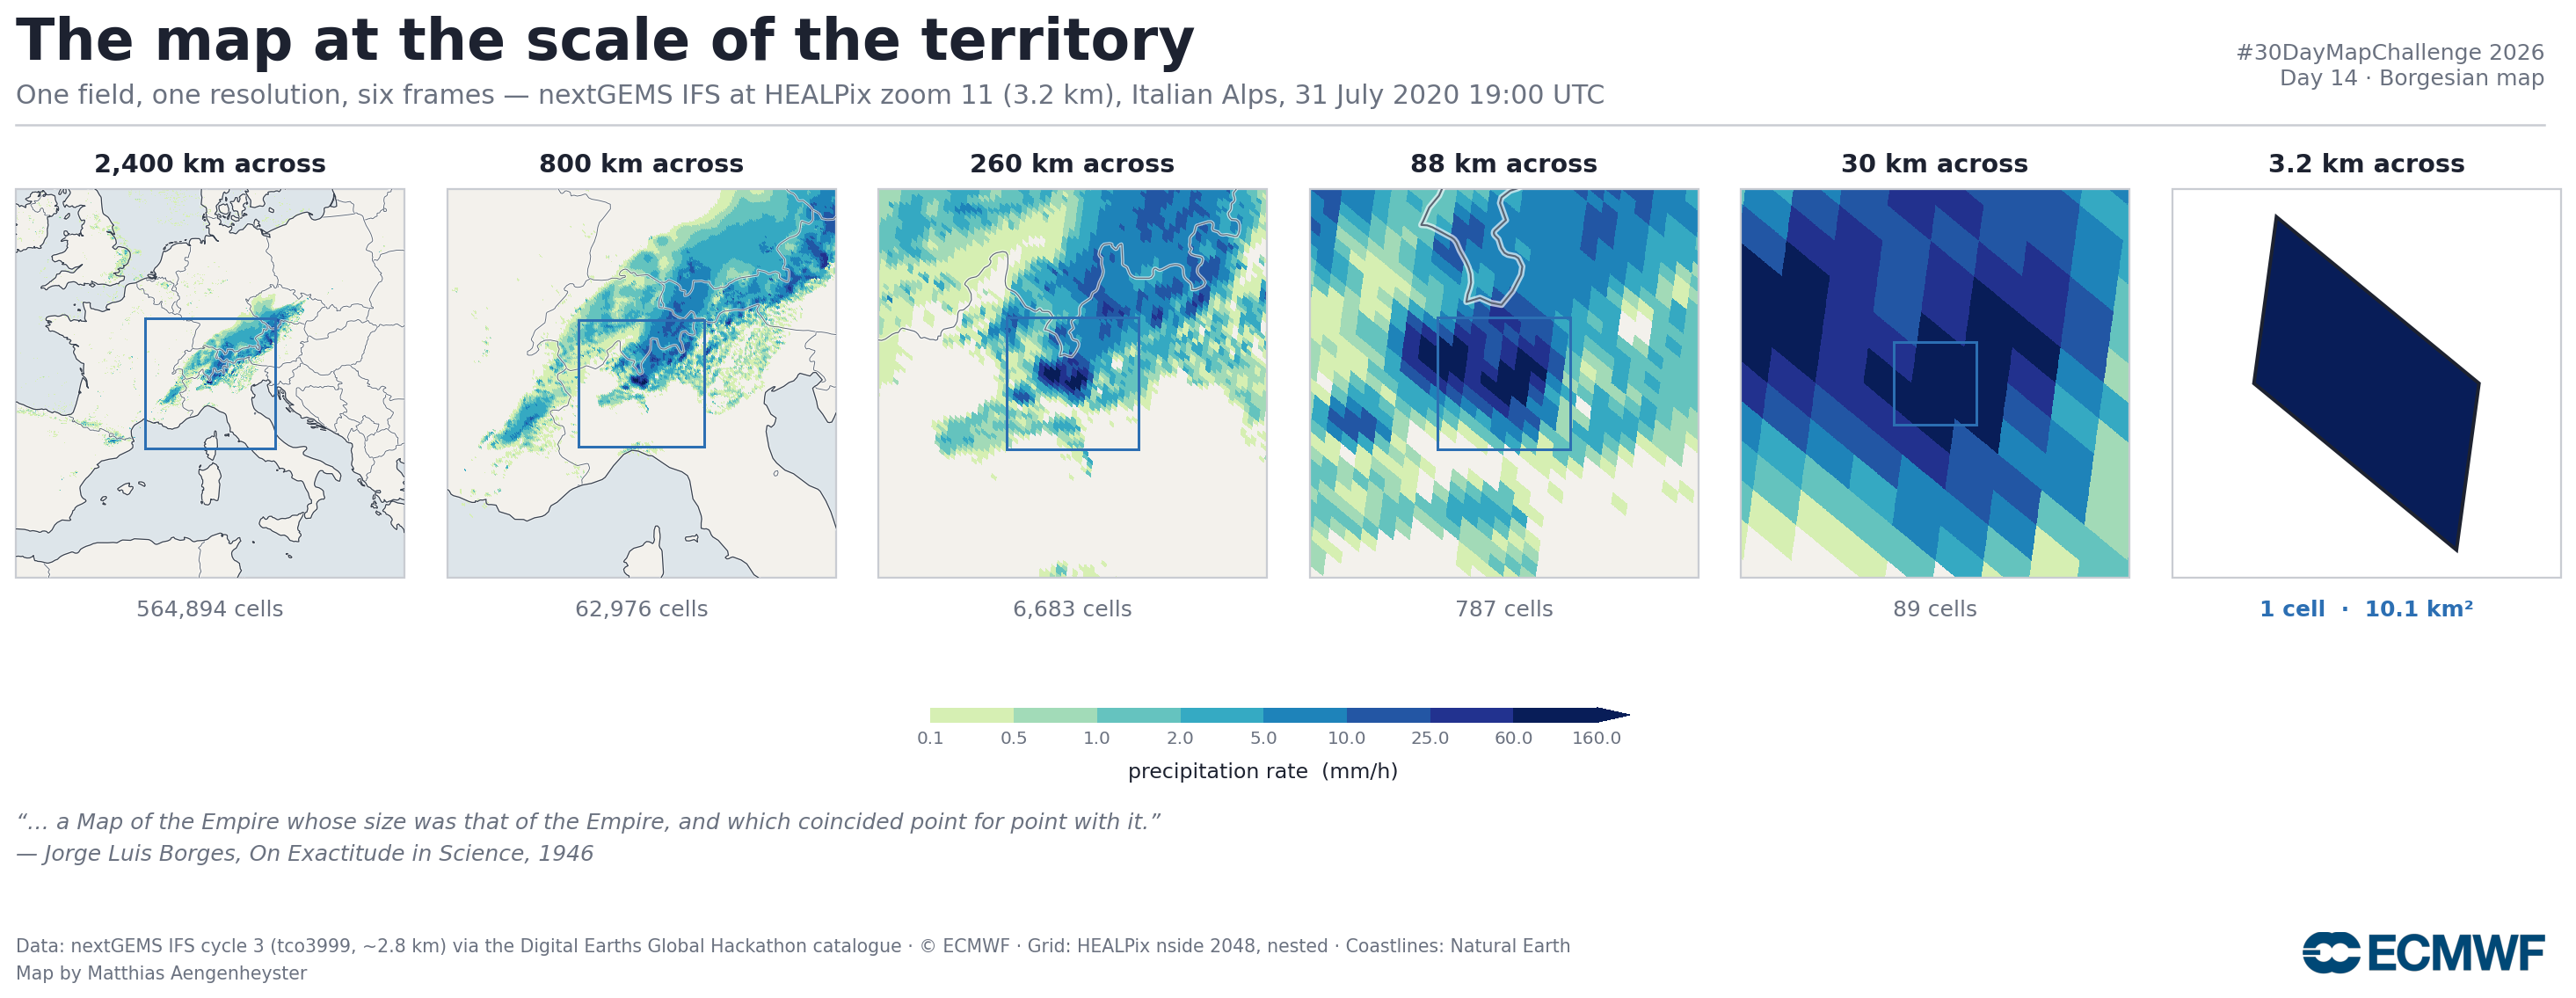

In [6]:
import matplotlib.pyplot as plt, matplotlib.image as mpimg
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Rectangle, Polygon

proj = ccrs.AzimuthalEquidistant(central_longitude=LON0, central_latitude=LAT0)

fig=plt.figure(figsize=(17,6.3),dpi=180); fig.patch.set_facecolor("white")
W,G,X0,Y0=0.1445,0.0158,0.030,0.430
H=W*17/6.3
for i,h in enumerate([x*1000.0 for x in HALF]):
    ax=fig.add_axes([X0+i*(W+G),Y0,W,H],projection=proj)
    ax.set_xlim(-h,h); ax.set_ylim(-h,h)
    if i < 5:
        basemap(ax, outlines=HALF[i]>10, scale="50m" if HALF[i]>300 else "10m",
                lw=0.8 if HALF[i]>300 else (1.0 if HALF[i]>100 else 1.9))
        img,ext=raster(None,field,NSIDE,ax,nx=1000,ny=1000); show(ax,img,ext)
    else:                       # the cell on its own -- nothing else is drawn
        ax.set_facecolor("white")
        img,ext=raster(np.array([PK]),np.array([field[PK]]),NSIDE,ax,nx=1000,ny=1000)
        show(ax,img,ext)
        b=hp.boundaries(NSIDE,PK,step=12,nest=True)
        lo,la=hp.vec2ang(b.T,lonlat=True); lo=np.where(lo>180,lo-360,lo)
        ax.add_patch(Polygon(proj.transform_points(PC,lo,la)[:,:2],
                             fill=False,ec=INK,lw=1.6,zorder=7))
        ax.spines["geo"].set_edgecolor(EDGE); ax.spines["geo"].set_linewidth(0.9)
    if i<5:                                      # where the next frame sits
        n=HALF[i+1]*1000.0
        ax.add_patch(Rectangle((-n,-n),2*n,2*n,fill=False,ec=ACC,lw=1.2,zorder=6))
    span=2*HALF[i]
    ax.text(0.5,1.045,"3.2 km across" if i==5 else "%s km across"%format(int(round(span)),","),
            transform=ax.transAxes,ha="center",color=INK,fontsize=11.5,fontweight="bold")
    if i==5:
        ax.text(0.5,-0.055,"1 cell  ·  %.1f km\u00b2"%CELL_KM2,transform=ax.transAxes,
                ha="center",va="top",color=ACC,fontsize=10,fontweight="bold")
    else:
        n=NCELL[i]
        ax.text(0.5,-0.055,"%s cells"%format(n,","),transform=ax.transAxes,
                ha="center",va="top",color=MUT,fontsize=10)

cax=fig.add_axes([0.37,0.285,0.26,0.015])
cb=fig.colorbar(ScalarMappable(norm=NORM,cmap=CMAP),cax=cax,orientation="horizontal",
                ticks=BINS,extend="max",spacing="uniform")
cb.set_label("precipitation rate  (mm/h)",color=INK,fontsize=9.5,labelpad=7)
cb.ax.tick_params(labelsize=8,colors=MUT,length=0); cb.outline.set_visible(False)

fig.text(0.030,0.950,"The map at the scale of the territory",color=INK,fontsize=26,fontweight="bold")
fig.text(0.030,0.906,"One field, one resolution, six frames — nextGEMS IFS at HEALPix zoom 11 "
         "(3.2 km), Italian Alps, 31 July 2020 19:00 UTC",color=MUT,fontsize=12)
fig.text(0.970,0.950,"#30DayMapChallenge 2026",color=MUT,fontsize=10,ha="right")
fig.text(0.970,0.924,"Day 14 · Borgesian map",color=MUT,fontsize=10,ha="right")
fig.lines.append(plt.Line2D([0.030,0.970],[0.884,0.884],transform=fig.transFigure,color=EDGE,lw=1.0))
fig.text(0.030,0.195,
 "“… a Map of the Empire whose size was that of the Empire, and which coincided point for point with it.”\n"
 "— Jorge Luis Borges, On Exactitude in Science, 1946",
 color=MUT,fontsize=10,style="italic",va="top",linespacing=1.6)
fig.text(0.030,0.055,"Data: nextGEMS IFS cycle 3 (tco3999, ~2.8 km) via the Digital Earths Global Hackathon catalogue · "
         "© ECMWF · Grid: HEALPix nside 2048, nested · Coastlines: Natural Earth", color=MUT,fontsize=8.2)
fig.text(0.030,0.028,"Map by Matthias Aengenheyster",
         color=MUT,fontsize=8.2)
try:
    a=fig.add_axes([0.880,0.026,0.090,0.055]); a.imshow(mpimg.imread("assets/ECMWF_Core_Logo_RGB.png")); a.axis("off")
except FileNotFoundError: pass
fig.savefig("day14_borgesian.png",facecolor="white")
print("saved day14_borgesian.png")

## Note

The last panel is not a failure of the plot. It is the model telling you where its knowledge
stops. Below 3.2 km this run has no opinion at all: not which valley the cell of rain sat in,
not which village was under it, not what time the river came up. Those are the questions
people actually ask after a flood, and they live one or two rungs below the finest global
simulation currently run anywhere.

Figure saved as `day14_borgesian.png`.

*Part of a #30DayMapChallenge 2026 series built on ECMWF (and Copernicus) open data.*